# Photonic Graph-State Architecture under Component Imperfections

A numerical framework for preparing ideal graph states and evaluating how graph topology, photon survival, heralded entangling operations, and Pauli noise influence state preparation.

The analysis combines exact small-system statevectors, stabilizer checks, density-matrix evolution, exhaustive error-pattern enumeration, Monte Carlo estimation, and graph-based operation scheduling. All numerical component parameters are illustrative rather than experimentally calibrated.

**Model scope.** Graph edges specify controlled-$Z$ gates in the ideal circuit. An independent heralded-success parameter is subsequently assigned to each edge. This construction is a phenomenological preparation model, not a microscopic optical fusion protocol or a quantum-dot emitter simulation.

**Execution.** Run the notebook from top to bottom with Python, NumPy, NetworkX, and Matplotlib. Qiskit is optional for an independent statevector cross-check. Vertices are numbered $0,\ldots,N-1$, with qubit $0$ identified with the least-significant computational-basis bit.


## 1. Mathematical foundations

For an undirected simple graph $G=(V,E)$, each vertex is a qubit and each edge specifies a CZ operation in the *ideal circuit construction*:

$$|G\rangle=\prod_{(i,j)\in E}CZ_{ij}|+\rangle^{\otimes N},\qquad |+\rangle=(|0\rangle+|1\rangle)/\sqrt2.$$

Stabilizer generators are $K_i=X_i\prod_{j\in N(i)}Z_j$, satisfying $K_i|G\rangle=|G\rangle$. For any simple undirected graph, the handshaking lemma states $\sum_i d_i=2|E|$. It provides a basic graph-validation check.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import product


## 2. Reusable model functions

In [2]:

def validate_graph(G):
    n = G.number_of_nodes()
    if n < 1 or set(G.nodes) != set(range(n)):
        raise ValueError('Graph must have consecutive integer vertices 0..N-1')
    if G.is_directed() or nx.number_of_selfloops(G):
        raise ValueError('Only simple undirected graphs without self-loops are supported')
    return n


def graph_statevector(G):
    """Exact pure graph-state vector, practical only for small N."""
    n = validate_graph(G)
    if n > 16:
        raise ValueError('Exact statevector limited to N <= 16')
    basis = np.arange(1 << n, dtype=np.uint32)
    parity = np.zeros(len(basis), dtype=np.uint8)
    for i, j in G.edges:
        parity ^= (((basis >> i) & 1) & ((basis >> j) & 1)).astype(np.uint8)
    return (1 - 2 * parity.astype(np.int8)).astype(complex) / np.sqrt(1 << n)


def stabilizer_label(G, vertex):
    """Pauli string in Qiskit order, qubit 0 on the right."""
    n = validate_graph(G)
    s = ['I'] * n
    s[vertex] = 'X'
    for j in G.neighbors(vertex):
        s[j] = 'Z'
    return ''.join(reversed(s))


def expectation_graph_stabilizer(G, vertex, state=None):
    """Compute <psi|K_vertex|psi> directly with basis bit operations."""
    n = validate_graph(G)
    if state is None:
        state = graph_statevector(G)
    k = np.arange(1 << n, dtype=np.uint32)
    z_sign = np.ones(len(k), dtype=np.int8)
    for j in G.neighbors(vertex):
        z_sign *= (1 - 2 * ((k >> j) & 1).astype(np.int8))
    # K |k> = z_sign(k) |k xor (1 << vertex)>
    return np.vdot(state[k ^ (1 << vertex)], z_sign * state)


def incidence_matrix_gf2(G):
    n = validate_graph(G)
    edges = list(G.edges)
    b = np.zeros((n, len(edges)), dtype=np.uint8)
    for c, (i, j) in enumerate(edges):
        b[i, c] = b[j, c] = 1
    return b


def analytical_success(G, eta, s):
    validate_graph(G)
    if not 0 <= eta <= 1 or not 0 <= s <= 1:
        raise ValueError('Probabilities must lie in [0,1]')
    return eta ** G.number_of_nodes() * s ** G.number_of_edges()


def exact_conditional_fidelity(G, p, q, max_edges=20):
    """Enumerate all edge ZZ patterns; include cancellation of Z errors mod 2."""
    b = incidence_matrix_gf2(G)
    n, e = b.shape
    if e > max_edges:
        raise ValueError(f'Exact enumeration limited to {max_edges} edges')
    if not 0 <= p <= 1 or not 0 <= q <= 1:
        raise ValueError('Probabilities must lie in [0,1]')
    fidelity = 0.0
    for bits in product((0, 1), repeat=e):
        edge_err = np.fromiter(bits, dtype=np.uint8, count=e)
        w = int(edge_err.sum())
        net = (b @ edge_err) % 2
        v = int(net.sum())
        fidelity += (q ** w) * ((1 - q) ** (e - w)) * (p ** v) * ((1 - p) ** (n - v))
    return float(fidelity)


def monte_carlo_architecture(G, eta, p, s, q, trials=100000, seed=42, batch=20000):
    """Sample survival, heralding, Z errors and edge ZZ errors (independent)."""
    b = incidence_matrix_gf2(G)
    n, e = b.shape
    if not isinstance(trials, int) or trials <= 0:
        raise ValueError('trials must be a positive integer')
    if not all(0 <= v <= 1 for v in (eta, p, s, q)):
        raise ValueError('Probabilities must lie in [0,1]')
    rng = np.random.default_rng(seed)
    n_success = n_overlap = 0
    for start in range(0, trials, batch):
        m = min(batch, trials - start)
        survive = np.all(rng.random((m, n)) < eta, axis=1)
        herald = np.all(rng.random((m, e)) < s, axis=1)
        accepted = survive & herald
        a = (rng.random((m, n)) < p).astype(np.uint8)
        edge = (rng.random((m, e)) < q).astype(np.uint8)
        net = (a + edge @ b.T) % 2
        overlap = accepted & np.all(net == 0, axis=1)
        n_success += int(accepted.sum())
        n_overlap += int(overlap.sum())
    return dict(P_accept=n_success/trials,
                F_conditional=n_overlap/n_success if n_success else np.nan,
                Q=n_overlap/trials, n_success=n_success,
                n_overlap=n_overlap, trials=trials, N=n, E=e)


def standard_error(p, n):
    return np.sqrt(p*(1-p)/n) if n and np.isfinite(p) else np.nan


def edge_schedule(G):
    """Proper edge coloring via greedy coloring of line graph; not necessarily optimal."""
    validate_graph(G)
    colors = nx.coloring.greedy_color(nx.line_graph(G), strategy='largest_first')
    rounds = {}
    for edge, color in colors.items():
        rounds.setdefault(color, []).append(edge)
    for edges in rounds.values():
        vertices = [v for edge in edges for v in edge]
        assert len(vertices) == len(set(vertices))
    return rounds


def phase_flip_density(rho, p, n, qubit):
    """Dense exact channel, only for small N. Computational basis bit i = qubit i."""
    if not 0 <= p <= 1:
        raise ValueError('p must lie in [0,1]')
    diag = 1 - 2 * ((np.arange(1 << n) >> qubit) & 1)
    return (1-p)*rho + p*(diag[:,None]*rho*diag[None,:])


def independent_dephasing_density(rho, p, n):
    for i in range(n):
        rho = phase_flip_density(rho, p, n, i)
    return rho


## 3. Graph topologies and connectivity

The comparison considers nine-qubit path, cycle, star, and $3\times3$ square-grid graphs. Grid vertices are relabelled with consecutive integer indices to maintain consistent qubit conventions.

Path     N= 9 E= 8 max_degree= 2 | handshaking OK
Cycle    N= 9 E= 9 max_degree= 2 | handshaking OK
Star     N= 9 E= 8 max_degree= 8 | handshaking OK
Grid     N= 9 E=12 max_degree= 4 | handshaking OK


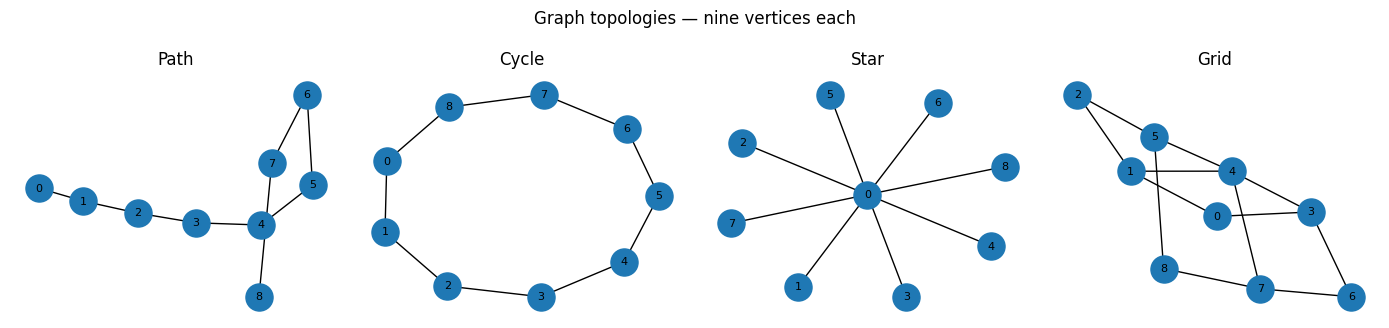

In [3]:
N = 9
graphs = {
    "Path": nx.path_graph(N),
    "Cycle": nx.cycle_graph(N),
    "Star": nx.star_graph(N - 1),
    "Grid": nx.convert_node_labels_to_integers(nx.grid_2d_graph(3, 3)),
}
for name, G in graphs.items():
    n, e = G.number_of_nodes(), G.number_of_edges()
    assert sum(dict(G.degree()).values()) == 2*e
    print(f"{name:8s} N={n:2d} E={e:2d} max_degree={max(dict(G.degree()).values()):2d} | handshaking OK")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, (name, G) in zip(axes, graphs.items()):
    nx.draw(G, pos=nx.spring_layout(G, seed=12), ax=ax, with_labels=True, node_size=380, font_size=8)
    ax.set_title(name)
fig.suptitle('Graph topologies — nine vertices each')
fig.tight_layout()
plt.show()

## 4. Ideal graph-state construction and stabilizer validation

The statevector calculation uses $(-1)^{\sum_{(i,j)\in E}x_ix_j}/\sqrt{2^N}$ for computational basis bitstring $\mathbf x$. Qubit index 0 corresponds to the least-significant bit (the convention used by Qiskit). These exact $2^N$-amplitude vectors are suitable for small graphs only.

The stabilizer check computes the action of $K_i$ directly on basis amplitudes. It is independent of the phase-flip Monte Carlo model below.

In [4]:
for name, G in graphs.items():
    state = graph_statevector(G)
    assert np.isclose(np.vdot(state, state).real, 1.0)
    values = [expectation_graph_stabilizer(G, i, state) for i in G.nodes()]
    assert all(np.isclose(v, 1.0) for v in values)
    print(f"{name:8s} | amplitudes: {len(state):4d} | stabilizers verified: {len(values)}")

small = nx.path_graph(3)
print('3-qubit stabilizer labels (Qiskit string order):',
      [stabilizer_label(small, i) for i in small.nodes()])

Path     | amplitudes:  512 | stabilizers verified: 9
Cycle    | amplitudes:  512 | stabilizers verified: 9
Star     | amplitudes:  512 | stabilizers verified: 9
Grid     | amplitudes:  512 | stabilizers verified: 9
3-qubit stabilizer labels (Qiskit string order): ['IZX', 'ZXZ', 'XZI']


## 5. Density matrices and independent dephasing

A random phase flip on qubit $i$ occurs with probability $p$:

$$\mathcal E_{p,i}(\rho)=(1-p)\rho+pZ_i\rho Z_i.$$

For independent dephasing on all $N$ graph-state qubits, the target fidelity is **exactly** $F=(1-p)^N$ in this model. The following calculation checks this expression independently using the full density matrix of a small graph state.

In [5]:
G_small = nx.path_graph(4)
psi = graph_statevector(G_small)
rho = np.outer(psi, psi.conj())
p = 0.1
rho_noisy = independent_dephasing_density(rho, p, len(G_small))
fidelity_from_matrix = float(np.vdot(psi, rho_noisy @ psi).real)
fidelity_analytical = (1 - p)**len(G_small)
assert np.isclose(np.trace(rho_noisy), 1.0)
assert np.allclose(rho_noisy, rho_noisy.conj().T)
assert np.linalg.eigvalsh(rho_noisy).min() >= -1e-12
assert np.isclose(fidelity_from_matrix, fidelity_analytical)
print(f"Density-matrix fidelity: {fidelity_from_matrix:.6f}")
print(f"Analytical fidelity:     {fidelity_analytical:.6f}")

Density-matrix fidelity: 0.656100
Analytical fidelity:     0.656100


## 6. Physical assumptions for architecture comparison

The preparation model distinguishes the following sources of imperfection:

- $\eta$: each photon independently survives with probability $\eta$.
- $s$: each *idealized edge operation* independently heralds success with probability $s$.
- $p$: each surviving qubit has an independent Pauli-$Z$ error probability $p$.
- $q$: each edge has an independent correlated $Z_i Z_j$ error probability $q$ after successful heralding.

**Acceptance:** Every photon and every edge operation must succeed; there are no retries or loss-recovery mechanisms.

**Success probability:** $P_{\rm accept}=\eta^N s^E$.

Let $B$ be the vertex-edge incidence matrix over $\mathrm{GF}(2)$, $\mathbf a$ an independent qubit-error vector and $\mathbf b$ an edge-error vector. The total Pauli-$Z$ pattern is $\mathbf z=\mathbf a+B\mathbf b\pmod 2$.

The *conditional* target-state fidelity of accepted trials is $F_{\rm cond}=\Pr(\mathbf z=\mathbf0)$, **including cancellation** of errors. The per-attempt weighted overlap is $Q=P_{\rm accept}F_{\rm cond}$.

The all-survival model and edge-as-operation assumption are not generic descriptions of photon-fusion networks.

## 7. Exact and Monte Carlo comparison of four architectures

The path and star are both nine-vertex trees with eight edges, but their conditional fidelities need not be identical when **both** local $Z_i$ faults and edge-associated $Z_iZ_j$ faults occur. Different incidence structures allow different joint cancellation patterns. The resulting difference here is very small; the analytical enumeration resolves it, whereas finite-shot Monte Carlo generally cannot.

In [6]:
eta, p, s, q = 0.98, 0.01, 0.97, 0.02
trials = 100_000
results = {}
print(f"{'Graph':8s} {'E':>3s} {'P_exact':>10s} {'P_MC':>10s} {'F_exact':>10s} {'F_MC':>10s} {'Q_MC':>10s}")
for name, G in graphs.items():
    mc = monte_carlo_architecture(G, eta, p, s, q, trials=trials, seed=42)
    ps = analytical_success(G, eta, s)
    f = exact_conditional_fidelity(G, p, q)
    results[name] = {'MC': mc, 'P_exact': ps, 'F_exact': f, 'Q_exact': ps*f}
    print(f"{name:8s} {G.number_of_edges():3d} {ps:10.6f} {mc['P_accept']:10.6f} {f:10.6f} {mc['F_conditional']:10.6f} {mc['Q']:10.6f}")
    assert abs(mc['P_accept']-ps) < 5*standard_error(ps, trials)
    assert abs(mc['F_conditional']-f) < 5*standard_error(f, mc['n_success'])
print('All analytical-versus-Monte-Carlo checks passed.')

Graph      E    P_exact       P_MC    F_exact       F_MC       Q_MC
Path       8   0.653444   0.652550   0.777200   0.776538   0.506730
Cycle      9   0.633841   0.631440   0.761658   0.760136   0.479980
Star       8   0.653444   0.652550   0.777201   0.776538   0.506730
Grid      12   0.578490   0.579440   0.716871   0.718073   0.416080
All analytical-versus-Monte-Carlo checks passed.


## 8. Visual comparison with statistical uncertainty

Monte Carlo estimates fluctuate. Error bars show an **approximate** 95% normal interval ($\pm 1.96\,\mathrm{SE}$) and may be inappropriate for rare-event probabilities. Exact enumeration provides an independent comparison for small graphs.

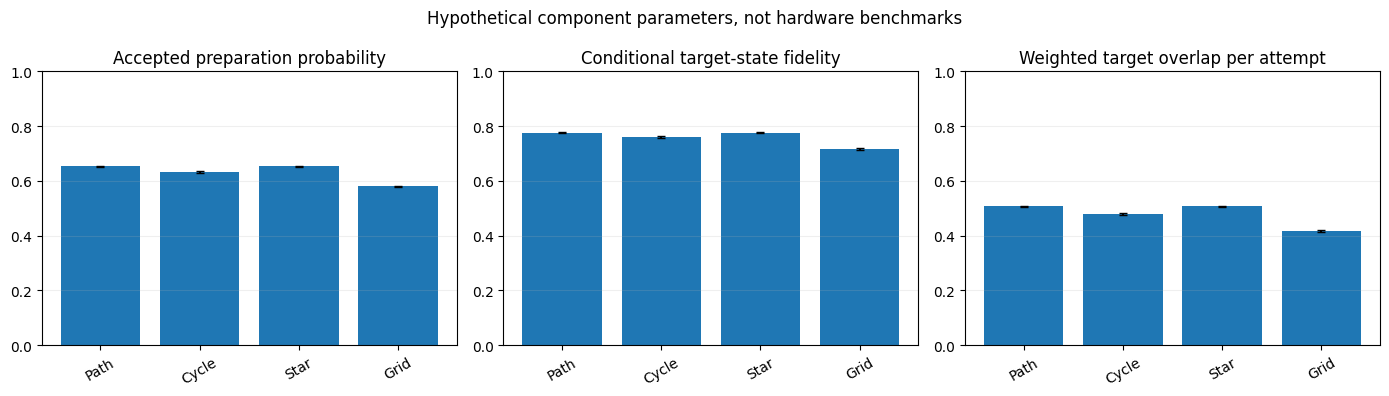

In [7]:
names = list(graphs)
x = np.arange(len(names))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, title, denom in [
    (axes[0], 'P_accept', 'Accepted preparation probability', 'trials'),
    (axes[1], 'F_conditional', 'Conditional target-state fidelity', 'n_success'),
    (axes[2], 'Q', 'Weighted target overlap per attempt', 'trials'),
]:
    vals = np.array([results[name]['MC'][metric] for name in names])
    errors = np.array([1.96*standard_error(results[name]['MC'][metric], results[name]['MC'][denom]) for name in names])
    ax.bar(names, vals, yerr=errors, capsize=3)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Hypothetical component parameters, not hardware benchmarks')
fig.tight_layout()
plt.show()

## 9. A crucial error-cancellation check

For $p=0$ and a tree with $E$ edges, $F=(1-q)^E$. For a cycle with $N$ edges, either no edge errors or all edge errors can cancel: $F=(1-q)^N+q^N$. Hence the naive product $(1-p)^N(1-q)^E$ is **not** exact for graphs with cycles.

In [8]:
n, q_test = 5, 0.2
G_path = nx.path_graph(n)
G_cycle = nx.cycle_graph(n)
F_path = exact_conditional_fidelity(G_path, 0, q_test)
F_cycle = exact_conditional_fidelity(G_cycle, 0, q_test)
assert np.isclose(F_path, (1-q_test)**(n-1))
assert np.isclose(F_cycle, (1-q_test)**n + q_test**n)
print('Path:', F_path, '| Cycle:', F_cycle, '| exact error cancellation verified')

Path: 0.4096000000000001 | Cycle: 0.32800000000000007 | exact error cancellation verified


## 10. Sensitivity analysis: vary edge-error probability

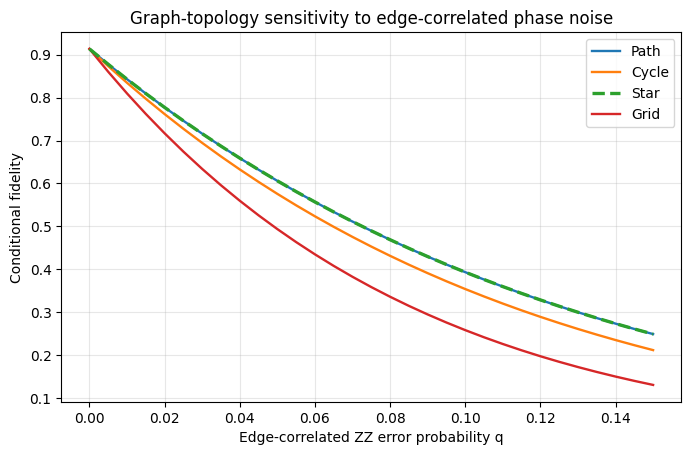

In [9]:
q_values = np.linspace(0, 0.15, 31)
fig, ax = plt.subplots(figsize=(8, 4.8))
for name, G in graphs.items():
    F_values = [exact_conditional_fidelity(G, p=0.01, q=float(q_val)) for q_val in q_values]
    ax.plot(q_values, F_values, label=name,
            linestyle='--' if name == 'Star' else '-',
            linewidth=2.4 if name == 'Star' else 1.7,
            zorder=3 if name == 'Star' else 2)
ax.set(xlabel='Edge-correlated ZZ error probability q', ylabel='Conditional fidelity',
       title='Graph-topology sensitivity to edge-correlated phase noise')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 11. Parallel scheduling as a simplified hardware resource

Assume an ideal CZ edge operation cannot share a qubit with another operation in the same round. A round is then a **matching**, and a proper edge coloring gives a valid schedule. The greedy algorithm is **not guaranteed optimal**. These are *circuit-operation rounds*, not actual optical time bins or quantum-dot emission schedules.

In [10]:
for name, G in graphs.items():
    sched = edge_schedule(G)
    print(f"{name:8s} | E={G.number_of_edges():2d} | max_degree={max(dict(G.degree()).values()):2d} | greedy rounds={len(sched)}")

Path     | E= 8 | max_degree= 2 | greedy rounds=3
Cycle    | E= 9 | max_degree= 2 | greedy rounds=3
Star     | E= 8 | max_degree= 8 | greedy rounds=8
Grid     | E=12 | max_degree= 4 | greedy rounds=4


## 12. Convergence of the Monte Carlo estimate

Use independent seeded runs at different sample sizes to inspect convergence toward the analytical success probability. Individual errors need **not** decrease monotonically, but typical uncertainty scales as $M^{-1/2}$.

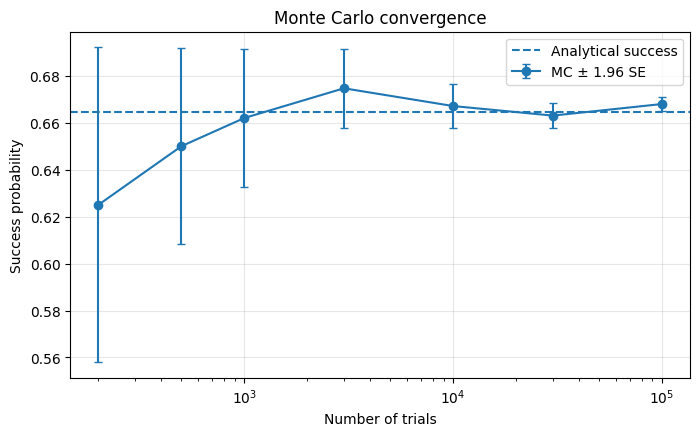

In [11]:
G = nx.cycle_graph(5)
Ms = np.array([200, 500, 1_000, 3_000, 10_000, 30_000, 100_000])
exact = analytical_success(G, 0.95, 0.97)
ests = []
errs = []
for idx, M in enumerate(Ms):
    r = monte_carlo_architecture(G, eta=0.95, p=0.02, s=0.97, q=0.01, trials=int(M), seed=42 + idx)
    ests.append(r['P_accept'])
    errs.append(1.96*standard_error(r['P_accept'], M))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(Ms, ests, yerr=errs, marker='o', capsize=3, label='MC ± 1.96 SE')
ax.axhline(exact, linestyle='--', label='Analytical success')
ax.set_xscale('log')
ax.set(xlabel='Number of trials', ylabel='Success probability', title='Monte Carlo convergence')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 13. Deterministic edge cases and model self-checks

These tests avoid relying on chance: perfect hardware, zero survival, and a fully deterministic Pauli-Z error. Conditional fidelity is undefined if **no preparation is accepted**.

In [12]:
G = nx.path_graph(5)
perfect = monte_carlo_architecture(G, 1, 0, 1, 0, trials=100)
assert (perfect['P_accept'], perfect['F_conditional'], perfect['Q']) == (1, 1, 1)
no_photons = monte_carlo_architecture(G, 0, 0.1, 1, 0, trials=100)
assert no_photons['P_accept'] == 0 and np.isnan(no_photons['F_conditional'])
all_z_errors = monte_carlo_architecture(G, 1, 1, 1, 0, trials=100)
assert all_z_errors['P_accept'] == 1 and all_z_errors['F_conditional'] == 0
print('All edge-case checks passed.')

All edge-case checks passed.


## 14. Optional independent Qiskit verification

If Qiskit is installed, validate a small graph's statevector using Hadamard/CZ gates. This cell **skips gracefully** when Qiskit is absent. It is not required to run the main analysis.

In [13]:
try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector
except ImportError:
    print('Qiskit not installed; optional cross-check skipped.')
else:
    test_graph = nx.path_graph(4)
    qc = QuantumCircuit(test_graph.number_of_nodes())
    for i in test_graph.nodes():
        qc.h(i)
    for i, j in test_graph.edges():
        qc.cz(i, j)
    expected = graph_statevector(test_graph)
    got = Statevector.from_instruction(qc).data
    assert np.allclose(got, expected)
    print('Qiskit independently agrees with exact graph-state construction.')

Qiskit not installed; optional cross-check skipped.


## 15. Results, interpretation, and limitations

### Verified within the specified model

1. Exact graph-state amplitudes satisfy normalization and the expected stabilizer relations for the tested small graphs.
2. Applying independent phase-flip channels to the density matrix reproduces the analytic target fidelity $F=(1-p)^N$.
3. With independent photon survival and edge-operation heralding, the accepted-preparation probability is $P_{\mathrm{accept}}=\eta^N s^{|E|}$.
4. Edge-associated $Z_iZ_j$ faults combine modulo two. Their cancellation patterns, including those associated with cycles, are captured by exact error-pattern enumeration.
5. Monte Carlo estimates are compared with exact small-system predictions using explicit statistical tolerances.
6. Graphs with identical numbers of qubits can differ in edge count, fault-cancellation structure, and valid parallel edge-operation schedules.

### Scope of the conclusions

The numerical study uses ideal graph-state preparation followed by a phenomenological noise model. No microscopic quantum-dot emission, spin--photon dynamics, photon indistinguishability, optical fusion implementation, feed-forward, loss-tolerant recovery, or logical error-correcting code is included. Edge operations are treated as idealized heralded events; their relation to laboratory hardware is protocol dependent. The graphs correspond to different target states, so their fidelity and success metrics do not establish a ranking of equivalent computational architectures.

### Extension: heterogeneous component noise

The next section examines a limitation of the homogeneous-component assumption: distinct photons can experience different survival probabilities and local phase-error rates. It introduces component-specific parameters, cross-checks the analytical predictions using density matrices and Monte Carlo sampling, and explores a hypothetical topology-dependent exposure law.

**Model distinction.** This is a complementary parameter scenario, not a cumulative addition of every noise mechanism above. In the extension, edge-heralding failures and correlated edge errors are omitted so that component heterogeneity can be isolated. The following code uses extension-specific graph and parameter variables, leaving the baseline graph set unchanged.


## 16. Extension — Heterogeneous Component Noise

### Motivation and model refinement

The baseline analysis assumes a common photon-survival probability $\eta$ and local phase-flip probability $p$ for all vertices. In practice, photonic paths and operating conditions can differ. This section instead assigns separate values $\eta_i$ and $p_i$ to individual photons and checks their effect on accepted-preparation probability and conditional fidelity.

A second, explicitly hypothetical sensitivity model relates the local dephasing probability to a graph-degree-dependent exposure time. This is not a microscopic quantum-dot emission model or a calibrated description of spin coherence.

### Computations

1. Compute analytical survival probability and conditional fidelity for nonidentical components.
2. Verify the phase-noise prediction using direct density-matrix evolution.
3. Compare simple topologies under the assumed exposure law.
4. Check the formulas with Monte Carlo sampling and deterministic limits.

**Scope.** Photon loss is treated as postselection, and dephasing is represented by independent local $Z$ faults. As noted above, this calculation deliberately does not include edge-heralding failures or correlated edge $Z_iZ_j$ faults. All numerical parameters are illustrative.


In [14]:
# Component parameters are independent of the baseline study above.
G_het = nx.path_graph(4)
n_het = G_het.number_of_nodes()
eta_het = np.array([0.96, 0.93, 0.91, 0.97])
p_het = np.array([0.01, 0.025, 0.035, 0.015])
assert np.all((eta_het >= 0) & (eta_het <= 1))
assert np.all((p_het >= 0) & (p_het <= 1))


### 16.1 Analytical heterogeneous model
For independent photon survival events, the probability that all required photons remain is
$$
P_{\mathrm{accept}}=\prod_{i=0}^{N-1}\eta_i.
$$
For independent Pauli-$Z_i$ errors on the surviving graph state, each nontrivial $Z$-pattern is orthogonal to the target, giving
$$
F_{\mathrm{cond}}=\prod_i(1-p_i),\qquad Q=P_{\mathrm{accept}}F_{\mathrm{cond}}.
$$
The model is **independent but non-identically distributed**, and separates loss from the quantum state on accepted events.

In [15]:
def heterogeneous_metrics(eta_values, p_values):
    """Independent local survival and Z-error probabilities; all-photon postselection."""
    eta_values = np.asarray(eta_values, dtype=float)
    p_values = np.asarray(p_values, dtype=float)
    if eta_values.ndim != 1 or eta_values.shape != p_values.shape:
        raise ValueError('Survival and phase-error arrays must be matching 1D arrays')
    if not (np.all((0 <= eta_values) & (eta_values <= 1))
            and np.all((0 <= p_values) & (p_values <= 1))):
        raise ValueError('All probabilities must lie in [0, 1]')
    accept = float(np.prod(eta_values))
    fidelity = float(np.prod(1 - p_values))
    return accept, fidelity, accept * fidelity

P_het, F_het, Q_het = heterogeneous_metrics(eta_het, p_het)
print(f'P(accept)={P_het:.6f}; F(conditioned)={F_het:.6f}; Q={Q_het:.6f}')


P(accept)=0.788075; F(conditioned)=0.917494; Q=0.723054


### 16.2 Statevector and density-matrix check
The shared Section 2 implementation constructs the ideal graph state with amplitudes $2^{-N/2}(-1)^{\sum_{(i,j)\in E}x_ix_j}$. Independent phase-flip channels are applied to its density matrix and verify the analytical result without Qiskit.

In [16]:
# Reuse the statevector and channel routines from Section 2.
psi_het = graph_statevector(G_het)
rho_het = np.outer(psi_het, psi_het.conj())
for qubit, p_i in enumerate(p_het):
    rho_het = phase_flip_density(rho_het, float(p_i), n_het, qubit)

F_matrix_het = float(np.vdot(psi_het, rho_het @ psi_het).real)
assert np.isclose(F_matrix_het, F_het)
assert np.isclose(np.trace(rho_het), 1)
assert np.linalg.eigvalsh(rho_het).min() >= -1e-12
print(f'Density-matrix fidelity: {F_matrix_het:.8f}')


Density-matrix fidelity: 0.91749426


### 16.3 Degree-dependent exposure hypothesis

As a controlled sensitivity model, suppose a qubit participating in more idealized edge operations accumulates a longer effective dephasing exposure. Let

$$
t_i=t_0+d_i t_g,\qquad p_i=\frac12\bigl(1-e^{-t_i/T_2}\bigr),
$$

where $d_i$ is the graph degree. The exponential law is an assumed phase-damping proxy: $t_i$ is not an experimentally determined quantum-dot spin history, and the construction does not capture correlated errors during sequential emission.

For a fixed total degree, $\ln(1-p_i)=\ln[(1+e^{-t_i/T_2})/2]$ is a convex function of the assumed exposure time. In this toy model, concentrating some of the exposure on a star hub can therefore increase the product $\prod_i(1-p_i)$ relative to distributing it across a path. This result is **specific to the degree-exposure assumption**: including idle-qubit dephasing throughout the full schedule can change the comparison.


graph | maximum p_i | F_cond | Q
Path | 0.0768 | 0.71384 | 0.58205
Star | 0.1296 | 0.71620 | 0.58397
Cycle | 0.0768 | 0.67077 | 0.54693


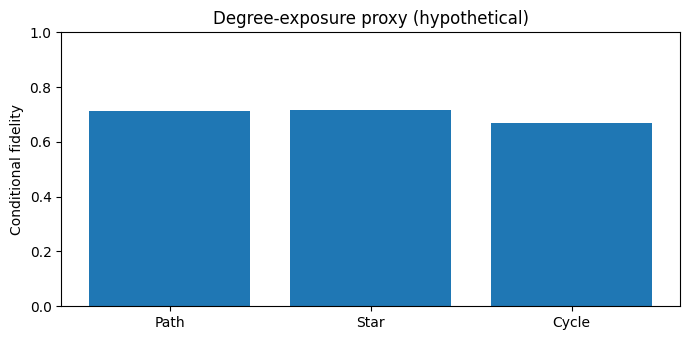

In [17]:
def degree_time_phase_prob(G, t0_ns=1.0, gate_ns=2.0, T2_ns=30.0):
    """Hypothetical degree-dependent local exposure law (not an emitter model)."""
    durations = np.array([
        t0_ns + G.degree(i) * gate_ns for i in range(len(G))
    ])
    return 0.5 * (1 - np.exp(-durations / T2_ns))


graphs_het = {
    'Path': nx.path_graph(5),
    'Star': nx.star_graph(4),
    'Cycle': nx.cycle_graph(5),
}
rows_het = []
for graph_name, graph_het in graphs_het.items():
    p_graph = degree_time_phase_prob(graph_het)
    P_graph, F_graph, Q_graph = heterogeneous_metrics(
        np.full(len(graph_het), 0.96), p_graph
    )
    rows_het.append((graph_name, float(p_graph.max()), F_graph, Q_graph))

print('graph | maximum p_i | F_cond | Q')
for graph_name, p_max, fidelity, weighted_overlap in rows_het:
    print(f'{graph_name} | {p_max:.4f} | {fidelity:.5f} | {weighted_overlap:.5f}')

fig_het, ax_het = plt.subplots(figsize=(7, 3.5))
ax_het.bar([r[0] for r in rows_het], [r[2] for r in rows_het])
ax_het.set_ylim(0, 1)
ax_het.set_ylabel('Conditional fidelity')
ax_het.set_title('Degree-exposure proxy (hypothetical)')
fig_het.tight_layout()
plt.show()


### 16.4 Monte Carlo validation
Estimate the all-photon acceptance and target-state overlap from independent Bernoulli draws. Analytical results, the density-matrix check, and Monte Carlo estimates are compared using five-standard-error bounds with the appropriate trial counts.

In [18]:
def run_heterogeneous_mc(eta_values, p_values, shots=100_000, seed=17):
    """Sample independent survival and Z-error events and return trial counts."""
    if not isinstance(shots, int) or shots <= 0:
        raise ValueError('shots must be a positive integer')
    rng = np.random.default_rng(seed)
    present = (rng.random((shots, len(eta_values))) < eta_values).all(axis=1)
    no_z = (rng.random((shots, len(p_values))) >= p_values).all(axis=1)
    n_accepted = int(present.sum())
    n_joint = int((present & no_z).sum())
    return {
        'P_accept': n_accepted / shots,
        'F_conditional': n_joint / n_accepted if n_accepted else np.nan,
        'Q': n_joint / shots,
        'n_accepted': n_accepted,
        'shots': shots,
    }


mc_het = run_heterogeneous_mc(eta_het, p_het)
truth_het = np.array([P_het, F_het, Q_het])
measured_het = np.array([
    mc_het['P_accept'], mc_het['F_conditional'], mc_het['Q']
])
print('analytic:', truth_het.round(5), 'MC:', measured_het.round(5))

# Binomial standard errors for P and Q use all shots. Conditional fidelity
# uses the accepted trials only; the tolerance accounts for sampling noise.
se_het = np.array([
    standard_error(P_het, mc_het['shots']),
    standard_error(F_het, mc_het['n_accepted']),
    standard_error(Q_het, mc_het['shots']),
])
assert np.all(np.abs(measured_het - truth_het) <= 5 * se_het + 1e-12)
assert np.allclose(heterogeneous_metrics(np.ones(4), np.zeros(4)), (1, 1, 1))
assert heterogeneous_metrics(np.array([1, 0]), np.zeros(2))[0] == 0
print('All extension checks passed (five-standard-error bounds).')


analytic: [0.78807 0.91749 0.72305] MC: [0.78794 0.91673 0.72233]
All extension checks passed (five-standard-error bounds).


### 16.5 Results and remaining limitations

The calculations extend the homogeneous model to **component-dependent survival and local dephasing**. Conditional target fidelity is verified against a density-matrix calculation, while Monte Carlo sampling checks the accepted-preparation probability and probability-weighted target overlap. A topology comparison illustrates the consequences of an explicitly assumed degree-dependent exposure law.

These extensions **do not** establish experimentally realistic emitter noise or a universal topology ranking. Missing physical mechanisms include measured source parameters, partial photon distinguishability and Hong--Ou--Mandel interference, spin--photon emission dynamics, temporal correlations, and noise from explicit optical fusion protocols.

A useful parameter-sensitivity check is

$$
\frac{\partial P_{\mathrm{accept}}}{\partial\eta_i}=\prod_{j\ne i}\eta_j.
$$